In [1]:
# Colab-ready: Interactive activation function comparison for a small MLP
# Paste this entire cell into a Google Colab notebook and run.

# --- (Optional) Install commonly-missing packages in some environments ---
# In Colab these are usually preinstalled. If you get ImportError, uncomment the pip lines below.
# !pip install -q ipywidgets
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu  # CPU-only fallback

# --- Imports ---
import math, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import ipywidgets as widgets

# Try to import PyTorch, if not available raise a clear error
try:
    import torch
    import torch.nn as nn
    import torch.optim as optim
    from torch.utils.data import TensorDataset, DataLoader
except Exception as e:
    raise ImportError(
        "PyTorch not found. In Google Colab, run `!pip install torch` (or enable GPU runtime and `pip` install the correct wheel). "
        "If you want a Keras/TensorFlow version instead, tell me and I'll provide it."
    )

# --- Reproducibility ---
RND = 42
np.random.seed(RND)
torch.manual_seed(RND)

# --- Dataset: 1D -> 1D nonlinear target (sinusoidal mixture) ---
def make_dataset(n=1000, noise=0.08, x_range=(-1.5, 1.5)):
    x = np.random.uniform(x_range[0], x_range[1], size=(n, 1)).astype(np.float32)
    # Nonlinear target combining frequencies (good to test approximation ability)
    y = np.sin(2 * np.pi * x) + 0.3 * np.sin(6 * np.pi * x)
    y += np.random.normal(0, noise, size=y.shape).astype(np.float32)
    return x, y

# --- Activations mapping ---
activations = {
    'ReLU': nn.ReLU(),
    'Sigmoid': nn.Sigmoid(),
    'Tanh': nn.Tanh(),
    'LeakyReLU': nn.LeakyReLU(negative_slope=0.01),
    'ELU': nn.ELU(alpha=1.0)
}

# --- Simple MLP (one hidden layer) ---
class SimpleMLP(nn.Module):
    def __init__(self, in_dim=1, hidden_dim=64, out_dim=1, activation='ReLU'):
        super().__init__()
        act = activations.get(activation, nn.ReLU())
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.act = act
        self.fc2 = nn.Linear(hidden_dim, out_dim)
    def forward(self, x):
        h_pre = self.fc1(x)           # pre-activation (useful to inspect gradients)
        h_act = self.act(h_pre)      # activation
        out = self.fc2(h_act)
        return out, h_pre, h_act

# --- Training / experiment function ---
def train_experiment(activation='ReLU',
                     epochs=200,
                     hidden_dim=64,
                     lr=1e-2,
                     batch_size=64,
                     train_size=800,
                     val_size=200,
                     noise=0.08,
                     device=None,
                     verbose=False):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # Create datasets
    x_train, y_train = make_dataset(train_size, noise)
    x_val, y_val = make_dataset(val_size, noise)
    ds = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True)
    model = SimpleMLP(1, hidden_dim, 1, activation).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {'train_loss': [], 'val_loss': [], 'grad_norms': [], 'dead_neurons': []}

    for ep in range(epochs):
        model.train()
        epoch_loss = 0.0
        grad_norm_epoch = 0.0
        for xb, yb in loader:
            xb = xb.to(device); yb = yb.to(device)
            opt.zero_grad()
            preds, h_pre, h_act = model(xb)
            loss = loss_fn(preds, yb)
            loss.backward()
            # Compute gradient norm across all parameters (L2)
            gnorm_sq = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    gnorm_sq += p.grad.detach().norm().item() ** 2
            grad_norm = math.sqrt(gnorm_sq)
            grad_norm_epoch = max(grad_norm_epoch, grad_norm)  # track max per batch this epoch
            opt.step()
            epoch_loss += loss.item() * xb.shape[0]
        epoch_loss /= len(ds)
        # validation
        model.eval()
        with torch.no_grad():
            val_preds, _, _ = model(torch.from_numpy(x_val).to(device))
            val_loss = loss_fn(val_preds, torch.from_numpy(y_val).to(device)).item()
            # Dead neurons: count hidden units whose activation is ~0 for all validation samples
            _, _, h_act_val = model(torch.from_numpy(x_val).to(device))
            act_np = h_act_val.cpu().numpy()  # shape (N, hidden_dim)
            # For ReLU: near-zero outputs => likely dead neuron. For others, near-constant small outputs.
            dead_count = np.sum(np.all(np.abs(act_np) < 1e-5, axis=0))
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['grad_norms'].append(grad_norm_epoch)
        history['dead_neurons'].append(int(dead_count))
        if verbose and (ep % max(1, epochs//5) == 0 or ep == epochs-1):
            print(f"[{activation}] ep {ep+1}/{epochs}: train={epoch_loss:.4f} val={val_loss:.4f} gnorm={grad_norm_epoch:.6f} dead={dead_count}")
    return model, history, (x_val, y_val)

# --- Helper plotting utilities ---
def plot_loss_curves(results, log_scale=True):
    plt.figure(figsize=(10,4))
    for act, (_, history, _) in results.items():
        t = history['train_loss']; v = history['val_loss']
        if log_scale:
            plt.semilogy(t, label=f"{act} train")
            plt.semilogy(v, linestyle='--', label=f"{act} val")
        else:
            plt.plot(t, label=f"{act} train")
            plt.plot(v, linestyle='--', label=f"{act} val")
    plt.title('Loss curves')
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_grad_norms(results):
    plt.figure(figsize=(10,4))
    for act, (_, history, _) in results.items():
        plt.plot(history['grad_norms'], label=act)
    plt.title('Gradient norms (per epoch, max batch norm shown)')
    plt.xlabel('Epoch'); plt.ylabel('Gradient norm (L2)')
    plt.legend(); plt.grid(True); plt.show()

def plot_dead_neurons(results):
    plt.figure(figsize=(10,4))
    for act, (_, history, _) in results.items():
        plt.plot(history['dead_neurons'], label=act)
    plt.title('Dead neurons (count) over epochs')
    plt.xlabel('Epoch'); plt.ylabel('Dead neuron count'); plt.legend(); plt.grid(True); plt.show()

def plot_approximations(results, x_range=(-1.5,1.5)):
    xv = np.linspace(x_range[0], x_range[1], 400).astype(np.float32)[:, None]
    y_true = np.sin(2 * np.pi * xv) + 0.3 * np.sin(6 * np.pi * xv)
    n = len(results)
    cols = min(3, n); rows = (n + cols - 1) // cols
    fig, axs = plt.subplots(rows, cols, figsize=(4*cols, 3*rows))
    axs = np.array(axs).reshape(-1)
    for i, (act, (model, history, (xv_val, yv_val))) in enumerate(results.items()):
        model.eval()
        device = next(model.parameters()).device
        with torch.no_grad():
            preds, _, _ = model(torch.from_numpy(xv).to(device))
        preds = preds.cpu().numpy()
        ax = axs[i]
        ax.plot(xv, y_true, label='true')
        ax.plot(xv, preds, label='pred')
        ax.scatter(xv_val, yv_val, alpha=0.12, s=8)
        ax.set_title(act)
        ax.legend()
    # Hide empty axes
    for j in range(i+1, len(axs)):
        axs[j].axis('off')
    plt.tight_layout(); plt.show()

# --- Interactive UI (ipywidgets) ---
act_select = widgets.SelectMultiple(
    options=list(activations.keys()),
    value=['ReLU', 'Tanh'],
    description='Activations',
    rows=5
)

epochs_slider = widgets.IntSlider(value=300, min=20, max=2000, step=20, description='epochs')
hidden_slider = widgets.IntSlider(value=64, min=8, max=512, step=8, description='hidden')
lr_box = widgets.FloatLogSlider(value=1e-2, base=10, min=-5, max=-1, step=0.1, description='lr')
batch_slider = widgets.IntSlider(value=64, min=8, max=512, step=8, description='batch')
run_button = widgets.Button(description='Run comparison', button_style='success')
device_label = widgets.Label(value=f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
seed_box = widgets.IntText(value=RND, description='seed')

out = widgets.Output(layout={'border': '1px solid black'})

def on_run(_):
    # Execute experiments for selected activations
    with out:
        clear_output(wait=True)
        selected = list(act_select.value)
        if not selected:
            print("Choose at least one activation function.")
            return
        # Set seed
        s = int(seed_box.value)
        np.random.seed(s)
        torch.manual_seed(s)

        results = {}
        total = len(selected)
        for idx, act in enumerate(selected, 1):
            print(f"[{idx}/{total}] Training {act} ...")
            start = time.time()
            model, history, valset = train_experiment(
                activation=act,
                epochs=int(epochs_slider.value),
                hidden_dim=int(hidden_slider.value),
                lr=float(lr_box.value),
                batch_size=int(batch_slider.value),
                device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
                verbose=False
            )
            elapsed = time.time() - start
            print(f" -> Completed {act} in {elapsed:.1f}s | final val loss {history['val_loss'][-1]:.4f} | dead {history['dead_neurons'][-1]}")
            results[act] = (model, history, valset)
        print("\nPlotting comparisons...")
        # Plot loss curves
        plot_loss_curves(results, log_scale=True)
        # Plot gradient norms
        plot_grad_norms(results)
        # Plot dead neurons
        plot_dead_neurons(results)
        # Plot approximations
        plot_approximations(results)
        print("\nDone. Inspect plots above for vanishing gradients (small gradient norms), dead neurons (counts), "
              "and approximation quality (true vs pred). Use different hidden sizes / lr / epochs to see effects.")

run_button.on_click(on_run)

# Layout & display
controls = widgets.VBox([
    widgets.HBox([act_select, widgets.VBox([epochs_slider, hidden_slider, lr_box, batch_slider, seed_box, run_button, device_label])])
])
display(controls, out)

# Tips for teacher/demo:
print("\nTips: Try selecting only 'Sigmoid' or 'Tanh' and use a larger hidden size and many epochs to observe smaller gradient norms (vanishing) vs. ReLU/LeakyReLU/ELU. "
      "To see dead neurons, focus on ReLU and increase the hidden dimension or decrease learning rate.")

Output(layout=Layout(border='1px solid black'))


Tips: Try selecting only 'Sigmoid' or 'Tanh' and use a larger hidden size and many epochs to observe smaller gradient norms (vanishing) vs. ReLU/LeakyReLU/ELU. To see dead neurons, focus on ReLU and increase the hidden dimension or decrease learning rate.


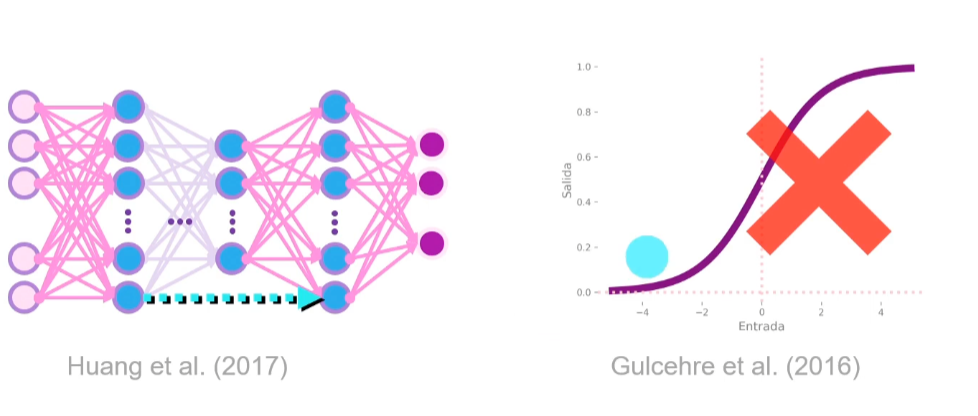

Referencia: https://www.youtube.com/watch?v=k3qvYATh77I

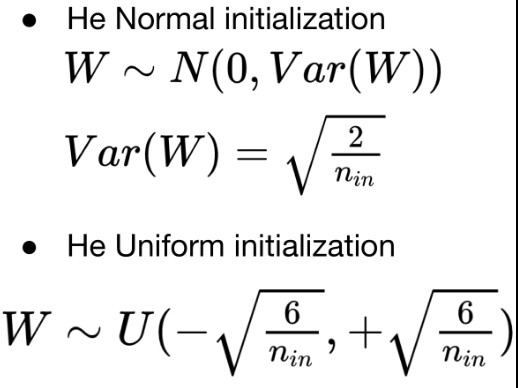

Búsqueda en google: "he initialization"

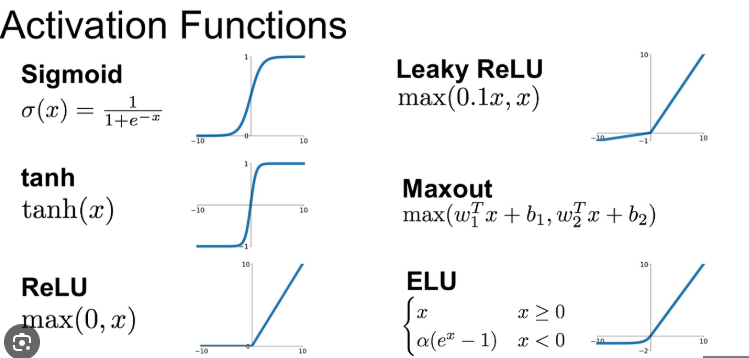